# 01 · Engine validation

This notebook checks that the 21 Rivals engine (`rivals/`) gets blackjack right before anything is built on it. It only *calls* the engine: every chart, house edge and probability below comes from `rivals.solver` or from rounds played through `rivals.resolve.play_round`.

**The game.** 21 Rivals (DraftKings) is head-to-head blackjack: two players each play 5 rounds from 1,000 chips on identical shuffled shoes, and the higher final balance wins. The rules confirmed in the app differ from the textbook game in three ways that matter here:

| | Textbook (6 decks, S17, DAS) | 21 Rivals |
|---|---|---|
| Doubling | any first two cards | only when the hand shows 9, 10 or 11 (soft A,8 and A,9 count, as 9/19 and 10/20) |
| Dealer checks for blackjack | under an ace **and** a ten | under an ace only: doubles and splits against a ten can lose to a hidden blackjack |
| Split aces | one card each | may be hit (and doubled on 9–11) |

Shared by both: 6 decks, dealer stands on all 17s, blackjack pays 3:2, one split, double after split, no surrender. Values are in **units of the starting bet** unless stated otherwise; the house edge is the expected loss per unit bet.

What the sections show:
1. the basic-strategy chart under both rule sets, and exactly which cells the rule changes move;
2. house edge and the spread of one round, optimal vs chart play;
3. simulated rounds converging on the exact values;
4. how much the (unconfirmed) deck count matters;
5. the dealer's outcome probabilities by upcard.

In [1]:
import sys, pathlib, time, logging

try:
    import rivals
except ImportError:  # kernel started without the project's editable install on its path
    sys.path.insert(0, str(pathlib.Path.cwd().parent))
    import rivals

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch, Rectangle

from rivals import DEFAULT_RULES
from rivals.resolve import play_round
from rivals.shoe import Shoe
from rivals.solver import BasicStrategy, Solver, basic_chart, solver_for
from rivals.solver.exact import VALUE_NAMES, counts_of, total_of

%matplotlib inline
%config InlineBackend.figure_formats = ["png"]
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

# Light chart surface, recessive grey chrome, one fixed colour per action.
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SURFACE, NEUTRAL = "#fcfcfb", "#f0efec"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
ACTION_COLOR = {"S": "#2a78d6", "H": "#eda100", "D": "#008300", "P": "#e87ba4"}
LABEL_INK = {"S": "#ffffff", "H": INK, "D": "#ffffff", "P": "#ffffff"}  # text inside each fill

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110,
    "font.family": ["Helvetica Neue", "Arial", "DejaVu Sans"], "font.size": 10,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "legend.frameon": False, "legend.fontsize": 9,
})
pd.set_option("display.width", 160)

RIVALS = DEFAULT_RULES
TEXTBOOK = DEFAULT_RULES.with_(double_totals=None, dealer_peeks_on_ten=True, hit_split_aces=False)
print("21 Rivals rules:", RIVALS.num_decks, "decks; double on", RIVALS.double_totals,
      "; check under a ten:", RIVALS.dealer_peeks_on_ten, "; hit split aces:", RIVALS.hit_split_aces)

21 Rivals rules: 6 decks; double on (9, 10, 11) ; check under a ten: False ; hit split aces: True


## 1. Basic strategy under both rule sets

`basic_chart(rules)` derives a total-dependent chart from the exact solver: for every hard total, soft total and pair against every upcard it picks the action with the highest expected value, averaging over the two-card hands that make the total. Solving one rule set takes about 6 seconds.

To say *why* each cell changes, the textbook game is also solved with one 21 Rivals rule switched on at a time. A changed cell is attributed to a rule when that single change reproduces it.

In [2]:
t0 = time.perf_counter()
charts = {"21 Rivals": basic_chart(RIVALS), "Textbook": basic_chart(TEXTBOOK)}
print(f"two rule sets solved in {time.perf_counter() - t0:.0f} s")

two rule sets solved in 12 s


In [3]:
ONE_RULE = {  # the textbook game with exactly one 21 Rivals rule switched on
    "Rule 1: double only on 9, 10 or 11": TEXTBOOK.with_(double_totals=RIVALS.double_totals),
    "Rule 2: no blackjack check under a ten": TEXTBOOK.with_(dealer_peeks_on_ten=False),
    "Rule 3: split aces may be hit": TEXTBOOK.with_(hit_split_aces=True),
}
t0 = time.perf_counter()
one_rule_charts = {name: basic_chart(rules) for name, rules in ONE_RULE.items()}
print(f"three single-rule variants solved in {time.perf_counter() - t0:.0f} s")

three single-rule variants solved in 17 s


In [4]:
UP_ORDER = [1, 2, 3, 4, 5, 6, 7, 8, 9, 0]  # value indices of upcards 2..9, T, A
SECTIONS = [  # (kind, heading, rows from top to bottom)
    ("hard", "Hard totals", list(range(20, 4, -1))),
    ("soft", "Soft totals", list(range(20, 12, -1))),
    ("pair", "Pairs", [0, 9, 8, 7, 6, 5, 4, 3, 2, 1]),
]


def chart_cells(chart):
    # {(kind, row, upcard): label} read from a Chart; an unsplit pair shows the chart's play for its total.
    cells = {}
    for kind, _, rows in SECTIONS:
        for row in rows:
            for up in UP_ORDER:
                if kind == "pair":
                    total, soft = total_of(counts_of([row, row]))
                    as_total = (chart.soft if soft else chart.hard)[(total, up)]
                    cells[(kind, row, up)] = "P" if chart.split[(row, up)] else str(as_total)
                else:
                    cells[(kind, row, up)] = str((chart.hard if kind == "hard" else chart.soft)[(row, up)])
    return cells


def row_label(kind, row):
    if kind == "hard":
        return str(row)
    if kind == "soft":
        return f"A,{row - 11}"
    return f"{VALUE_NAMES[row]},{VALUE_NAMES[row]}"


def cell_name(key):
    kind, row, up = key
    if kind == "hard":
        hand = f"hard {row}"
    elif kind == "soft":
        hand = f"soft {row} (A,{'A' if row == 12 else row - 11})"
    else:
        hand = row_label(kind, row)
    return f"{hand} vs {VALUE_NAMES[up]}"


def chart_layout():
    ys, headers, y = {}, [], 0.0
    for kind, heading, rows in SECTIONS:
        headers.append((heading, y))
        y += 0.9
        for row in rows:
            ys[(kind, row)] = y
            y += 1
        y += 0.5
    return ys, headers, y


def draw_chart(ax, cells, title, changed=None, before=None, change_fontsize=7.5):
    # One chart as a grid of cells; with `changed`, only those cells are coloured and show before→after.
    ys, headers, height = chart_layout()
    gap = 0.06
    for (kind, row, up), label in cells.items():
        x, y = UP_ORDER.index(up), ys[(kind, row)]
        action = label[0]
        if changed is None or (kind, row, up) in changed:
            face, ink, weight = ACTION_COLOR[action], LABEL_INK[action], "bold"
            text = label if changed is None else f"{before[(kind, row, up)]}→{label}"
        else:
            face, ink, weight, text = NEUTRAL, "#b3b1aa", "normal", label
        ax.add_patch(Rectangle((x + gap, y + gap), 1 - 2 * gap, 1 - 2 * gap, facecolor=face, edgecolor="none"))
        ax.text(x + 0.5, y + 0.53, text, ha="center", va="center", color=ink, fontweight=weight,
                fontsize=8.5 if len(text) <= 2 else change_fontsize)
    for heading, y in headers:
        ax.text(-0.15, y + 0.45, heading, ha="right", va="center", fontsize=9.5, fontweight="bold")
    for (kind, row), y in ys.items():
        ax.text(-0.15, y + 0.5, row_label(kind, row), ha="right", va="center", fontsize=8.5, color=INK2)
    for i, up in enumerate(UP_ORDER):
        ax.text(i + 0.5, -0.35, VALUE_NAMES[up], ha="center", va="bottom", fontsize=9, color=INK2)
    ax.text(5, -1.25, "Dealer upcard", ha="center", va="bottom", fontsize=9.5, color=INK2)
    ax.set_xlim(-1.6, 10.05)
    ax.set_ylim(height, -1.4)
    ax.set_axis_off()
    ax.set_title(title, pad=22)
    return ys


cells = {name: chart_cells(chart) for name, chart in charts.items()}
changed = sorted(k for k in cells["21 Rivals"] if cells["21 Rivals"][k] != cells["Textbook"][k])

**Check against the published chart.** Under textbook rules the derived chart should be the published 6-deck, S17, double-after-split, no-surrender basic strategy (as printed by e.g. the Wizard of Odds). The reference below is typed in from that chart and compared cell by cell; `Dh`/`Ds` mean double if allowed, otherwise hit/stand, and an unsplit pair shows the play for its total.

In [5]:
PUBLISHED = {  # upcards 2 3 4 5 6 7 8 9 T A
    "hard": {**{t: "S S S S S S S S S S" for t in (20, 19, 18, 17)},
             **{t: "S S S S S H H H H H" for t in (16, 15, 14, 13)},
             12: "H H S S S H H H H H", 11: "Dh Dh Dh Dh Dh Dh Dh Dh Dh H",
             10: "Dh Dh Dh Dh Dh Dh Dh Dh H H", 9: "H Dh Dh Dh Dh H H H H H",
             **{t: "H H H H H H H H H H" for t in (8, 7, 6, 5)}},
    "soft": {20: "S S S S S S S S S S", 19: "S S S S S S S S S S", 18: "S Ds Ds Ds Ds S S H H H",
             17: "H Dh Dh Dh Dh H H H H H", 16: "H H Dh Dh Dh H H H H H", 15: "H H Dh Dh Dh H H H H H",
             14: "H H H Dh Dh H H H H H", 13: "H H H Dh Dh H H H H H"},
    "pair": {0: "P P P P P P P P P P", 9: "S S S S S S S S S S", 8: "P P P P P S P P S S",
             7: "P P P P P P P P P P", 6: "P P P P P P H H H H", 5: "P P P P P H H H H H",
             4: "Dh Dh Dh Dh Dh Dh Dh Dh H H", 3: "H H H P P H H H H H",
             2: "P P P P P P H H H H", 1: "P P P P P P H H H H"},
}
published = {(kind, row, up): label
             for kind, rows in PUBLISHED.items() for row, line in rows.items()
             for up, label in zip(UP_ORDER, line.split())}
mismatch = [cell_name(k) for k, label in published.items() if cells["Textbook"][k] != label]
print(f"textbook chart vs published chart: {len(published) - len(mismatch)} of {len(published)} cells agree",
      "" if not mismatch else f"; differ: {mismatch}")

textbook chart vs published chart: 340 of 340 cells agree 


**The charts.** Left: basic strategy for the confirmed 21 Rivals rules. Right: the textbook game.

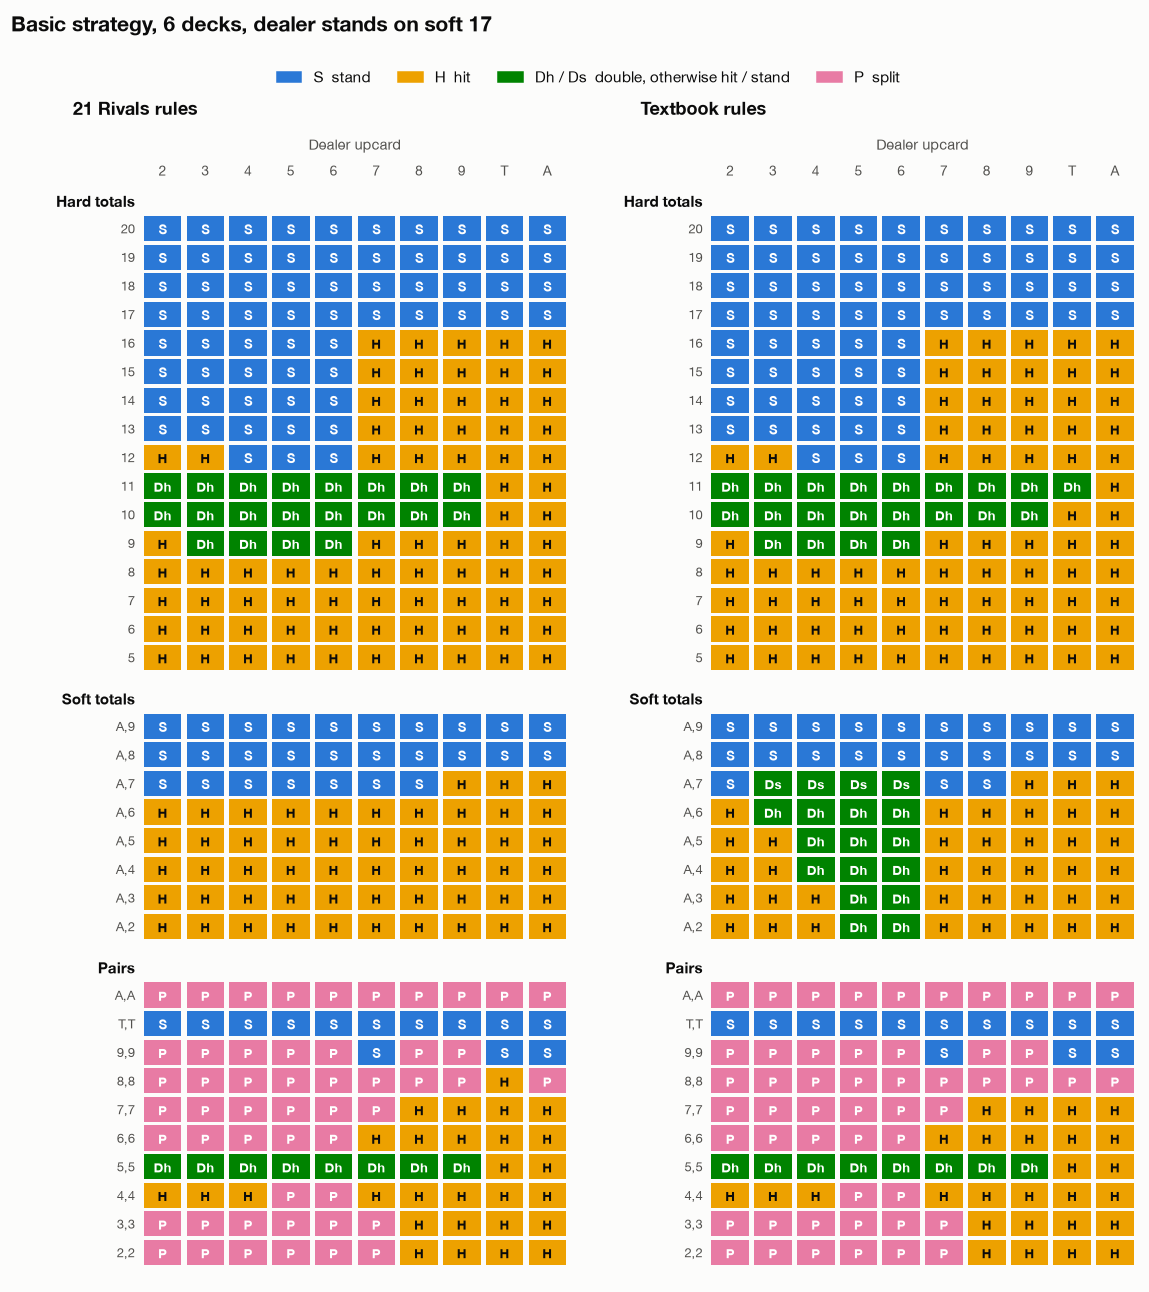

In [6]:
ACTION_HANDLES = [Patch(color=ACTION_COLOR["S"], label="S  stand"), Patch(color=ACTION_COLOR["H"], label="H  hit"),
                  Patch(color=ACTION_COLOR["D"], label="Dh / Ds  double, otherwise hit / stand"),
                  Patch(color=ACTION_COLOR["P"], label="P  split")]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 13.2))
draw_chart(axes[0], cells["21 Rivals"], "21 Rivals rules")
draw_chart(axes[1], cells["Textbook"], "Textbook rules")
fig.legend(handles=ACTION_HANDLES, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 0.955), fontsize=10,
           handlelength=1.6, columnspacing=1.8)
fig.suptitle("Basic strategy, 6 decks, dealer stands on soft 17", x=0.08, y=0.985, ha="left",
             fontsize=14, fontweight="bold")
fig.subplots_adjust(top=0.89, wspace=0.14)
plt.show()

**What changed and why.** Only the cells that differ are coloured, by the 21 Rivals play, and labelled *textbook→21 Rivals*; the bracket names the rule whose change on its own reproduces them.

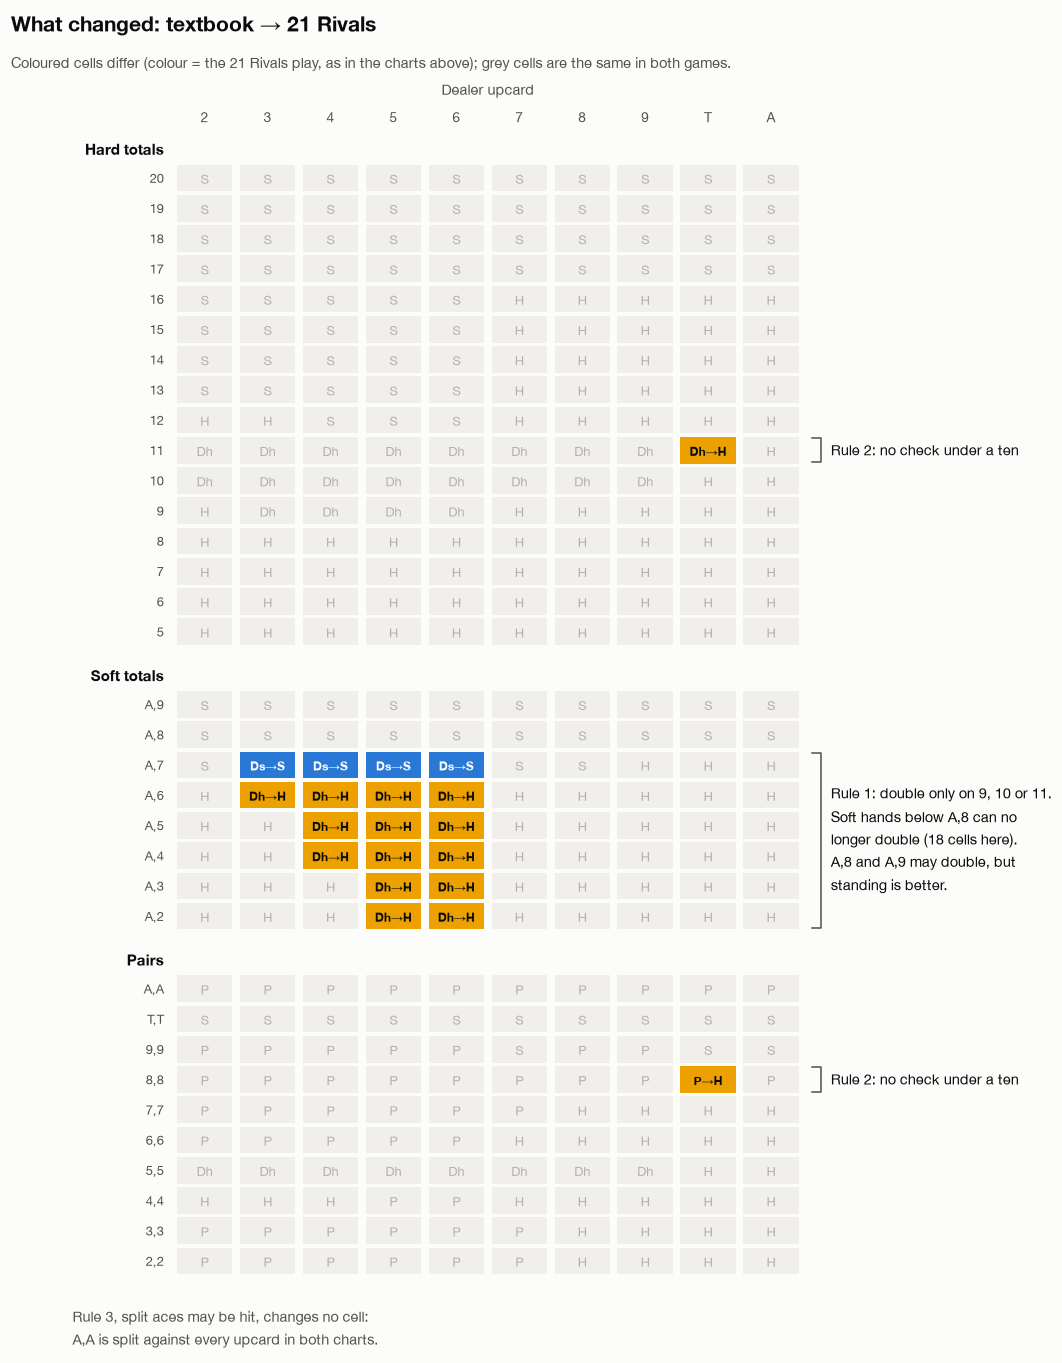

Rule 2: no blackjack check under a ten: 2 cells
   hard 11 vs T: Dh -> H; 8,8 vs T: P -> H
Rule 1: double only on 9, 10 or 11: 18 cells
   soft 13 (A,2) vs 5: Dh -> H; soft 13 (A,2) vs 6: Dh -> H; soft 14 (A,3) vs 5: Dh -> H; soft 14 (A,3) vs 6: Dh -> H; soft 15 (A,4) vs 4: Dh -> H; soft 15 (A,4) vs 5: Dh -> H; soft 15 (A,4) vs 6: Dh -> H; soft 16 (A,5) vs 4: Dh -> H; soft 16 (A,5) vs 5: Dh -> H; soft 16 (A,5) vs 6: Dh -> H; soft 17 (A,6) vs 3: Dh -> H; soft 17 (A,6) vs 4: Dh -> H; soft 17 (A,6) vs 5: Dh -> H; soft 17 (A,6) vs 6: Dh -> H; soft 18 (A,7) vs 3: Ds -> S; soft 18 (A,7) vs 4: Ds -> S; soft 18 (A,7) vs 5: Ds -> S; soft 18 (A,7) vs 6: Ds -> S


In [7]:
# Which single rule change reproduces each changed cell?
one_rule_cells = {name: chart_cells(chart) for name, chart in one_rule_charts.items()}
responsible = {k: [name for name, c in one_rule_cells.items() if c[k] == cells["21 Rivals"][k]] for k in changed}
groups = {}
for k in changed:
    groups.setdefault(" / ".join(responsible[k]) or "interaction of rules", []).append(k)

fig, ax = plt.subplots(figsize=(8.6, 13.2))
ys = draw_chart(ax, cells["21 Rivals"], "", changed=set(changed), before=cells["Textbook"], change_fontsize=8)
fig.suptitle("What changed: textbook → 21 Rivals", x=0.06, y=0.992, ha="left", fontsize=14, fontweight="bold")
fig.text(0.06, 0.962, "Coloured cells differ (colour = the 21 Rivals play, as in the charts above); "
         "grey cells are the same in both games.", fontsize=9.5, color=INK2, ha="left", va="top")


def callout(top_row, bottom_row, text):
    y0, y1 = ys[top_row] + 0.1, ys[bottom_row] + 0.9
    ax.plot([10.15, 10.3, 10.3, 10.15], [y0, y0, y1, y1], color=INK2, lw=1, clip_on=False)
    ax.text(10.45, (y0 + y1) / 2, text, ha="left", va="center", fontsize=9.5, clip_on=False, linespacing=1.35)


n_soft_shown = sum(1 for k in changed if k[0] == "soft")
callout(("soft", 18), ("soft", 13),
        f"Rule 1: double only on 9, 10 or 11.\nSoft hands below A,8 can no\nlonger double ({n_soft_shown} cells here).\nA,8 and A,9 may double, but\nstanding is better.")
callout(("hard", 11), ("hard", 11), "Rule 2: no check under a ten")
callout(("pair", 7), ("pair", 7), "Rule 2: no check under a ten")
ax.text(-1.6, chart_layout()[2] + 0.5,
        "Rule 3, split aces may be hit, changes no cell:\nA,A is split against every upcard in both charts.",
        fontsize=9.5, color=INK2, va="top", linespacing=1.35)
fig.subplots_adjust(top=0.935)
plt.show()

for rule, keys in groups.items():
    print(f"{rule}: {len(keys)} cells")
    print("   " + "; ".join(f"{cell_name(k)}: {cells['Textbook'][k]} -> {cells['21 Rivals'][k]}" for k in keys))

The chart cells shown are not the whole story for rule 1: the textbook game also doubles an unsplit A,A (soft 12) against a 6, which rule 1 removes too, but A,A is always split so that cell never comes up. The full list of cell differences, including that hidden one:

In [8]:
def all_cells(chart):
    # Every cell of the chart object, including rows the figure leaves out (hard 4, soft 12).
    out = {("hard", t, u): str(c) for (t, u), c in chart.hard.items()}
    out.update({("soft", t, u): str(c) for (t, u), c in chart.soft.items()})
    out.update({("pair", p, u): ("P" if s else "no split") for (p, u), s in chart.split.items()})
    return out


full = {name: all_cells(chart) for name, chart in charts.items()}
full_one = {name: all_cells(chart) for name, chart in one_rule_charts.items()}
rows = []
for k in sorted(full["Textbook"], key=lambda k: (["hard", "soft", "pair"].index(k[0]), -k[1], UP_ORDER.index(k[2]))):
    if full["Textbook"][k] != full["21 Rivals"][k]:
        rows.append({"cell": cell_name(k), "textbook": full["Textbook"][k], "21 Rivals": full["21 Rivals"][k],
                     "reproduced by": ", ".join(n.split(":")[0] for n, c in full_one.items() if c[k] == full["21 Rivals"][k])
                     or "none (interaction)"})
diff_table = pd.DataFrame(rows)
print(f"{len(diff_table)} cells differ in total;", diff_table["reproduced by"].value_counts().to_dict())
diff_table

21 cells differ in total; {'Rule 1': 19, 'Rule 2': 2}


,cell,textbook,21 Rivals,reproduced by
0,hard 11 vs T,Dh,H,Rule 2
1,"soft 18 (A,7) vs 3",Ds,S,Rule 1
2,"soft 18 (A,7) vs 4",Ds,S,Rule 1
3,"soft 18 (A,7) vs 5",Ds,S,Rule 1
4,"soft 18 (A,7) vs 6",Ds,S,Rule 1
5,"soft 17 (A,6) vs 3",Dh,H,Rule 1
6,"soft 17 (A,6) vs 4",Dh,H,Rule 1
7,"soft 17 (A,6) vs 5",Dh,H,Rule 1
8,"soft 17 (A,6) vs 6",Dh,H,Rule 1
9,"soft 16 (A,5) vs 4",Dh,H,Rule 1


**What to conclude.** The engine reproduces the published textbook chart exactly, and every one of the 21 cells that the 21 Rivals rules change is explained by a single rule: 19 lost soft doubles (rule 1) and two plays against a ten that are no longer worth the risk of a hidden blackjack, 11 (hit instead of double) and 8,8 (hit instead of split) (rule 2). Being allowed to hit split aces (rule 3) moves no cell. For a player, the 21 Rivals chart is *simpler* than the textbook one: the only doubles left are hard 9, 10 and 11, and soft hands are just hit or stand.

## 2. House edge and the spread of one round

`solver_for(rules).round_value()` is the exact value of a round before the deal with composition-dependent optimal play; `Solver(rules, strategy=chart).round_value()` is the exact value of playing the chart instead. Both are per unit bet, with no insurance and no side bets.

In [9]:
t0 = time.perf_counter()
values = {}
for name, rules in (("Textbook", TEXTBOOK), ("21 Rivals", RIVALS)):
    values[name] = {"optimal": solver_for(rules).round_value(),
                    "chart": Solver(rules, strategy=charts[name]).round_value()}
print(f"solved in {time.perf_counter() - t0:.0f} s\n")

summary = pd.DataFrame({
    name: {
        "House edge, optimal play": f"{v['optimal'].house_edge:.3%}",
        "House edge, chart play": f"{v['chart'].house_edge:.3%}",
        "Cost of using the chart": f"{v['chart'].house_edge - v['optimal'].house_edge:.4%}",
        "SD of one round, optimal play": f"{v['optimal'].std:.3f}",
        "SD of one round, chart play": f"{v['chart'].std:.3f}",
    }
    for name, v in values.items()
}).T
summary

solved in 13 s



,"House edge, optimal play","House edge, chart play",Cost of using the chart,"SD of one round, optimal play","SD of one round, chart play"
Textbook,0.457%,0.460%,0.0031%,1.147,1.146
21 Rivals,0.473%,0.476%,0.0036%,1.105,1.105


The house edge barely moves between the two games because the rule changes pull in opposite directions. Re-solving the textbook game with one rule changed at a time (optimal play) splits the total:

In [10]:
base = values["Textbook"]["optimal"].house_edge
rows = [{"rules": "Textbook", "house edge": base, "change vs textbook": 0.0}]
for name, rules in ONE_RULE.items():
    edge = solver_for(rules).round_value().house_edge
    rows.append({"rules": "Textbook + " + name.split(": ")[1], "house edge": edge, "change vs textbook": edge - base})
rivals_edge = values["21 Rivals"]["optimal"].house_edge
rows.append({"rules": "21 Rivals (all three)", "house edge": rivals_edge, "change vs textbook": rivals_edge - base})
attribution = pd.DataFrame(rows).set_index("rules")
interaction = (rivals_edge - base) - attribution["change vs textbook"].iloc[1:4].sum()
print(f"sum of the three single-rule effects: {attribution['change vs textbook'].iloc[1:4].sum():+.3%};"
      f" interaction between them: {interaction:+.3%}")
attribution.style.format("{:+.3%}", subset=["change vs textbook"]).format("{:.3%}", subset=["house edge"])

sum of the three single-rule effects: +0.009%; interaction between them: +0.007%


,house edge,change vs textbook
rules,,
Textbook,0.457%,+0.000%
"Textbook + double only on 9, 10 or 11",0.552%,+0.095%
Textbook + no blackjack check under a ten,0.558%,+0.101%
Textbook + split aces may be hit,0.269%,-0.187%
21 Rivals (all three),0.473%,+0.016%


**What to conclude.** Under the 21 Rivals rules the house edge is **0.473%** with perfect play and **0.476%** with the chart; the textbook game gives 0.457% / 0.460%. These are exactly the figures recorded in `docs/DECISIONS.md` (S6 results table), and the textbook value sits in the range the literature gives for 6-deck S17 DAS without resplitting. Losing soft doubles and the check under a ten cost about 0.10 points each; hitting split aces gives back about 0.19 points.

For this project the more important number is the spread: one round has a standard deviation of about **1.105 units** under 21 Rivals rules, lower than the textbook game's 1.147 because there are fewer doubles. Memorising the chart instead of playing perfectly costs only 0.004 points of edge.

## 3. Simulated rounds converge on the exact values

The chart is played through the real round engine, `play_round`, on 600,000 freshly shuffled 6-deck shoes (`Shoe.from_seed([1, i])`, so the run is reproducible), betting 10 chips with an unlimited bankroll so doubles and splits are always affordable. Each round's net is divided by the bet. This takes about 20 seconds.

In [11]:
N_ROUNDS, SEED, BET = 600_000, 1, 10
policy = BasicStrategy(RIVALS)
nets = np.empty(N_ROUNDS)
t0 = time.perf_counter()
for i in range(N_ROUNDS):
    nets[i] = play_round(Shoe.from_seed([SEED, i], RIVALS.num_decks), policy, BET, rules=RIVALS).net / BET
print(f"{N_ROUNDS:,} rounds in {time.perf_counter() - t0:.0f} s")

exact = values["21 Rivals"]["chart"]
mean, se = nets.mean(), nets.std(ddof=1) / np.sqrt(N_ROUNDS)
print(f"simulated mean {mean:+.3%} ± {1.96 * se:.3%} (95%)   exact chart EV {exact.ev:+.3%}   "
      f"difference {(mean - exact.ev) / se:+.2f} standard errors")
print(f"simulated SD {nets.std(ddof=1):.4f}   exact SD {exact.std:.4f}")

600,000 rounds in 24 s
simulated mean -0.535% ± 0.280% (95%)   exact chart EV -0.476%   difference -0.41 standard errors
simulated SD 1.1052   exact SD 1.1052


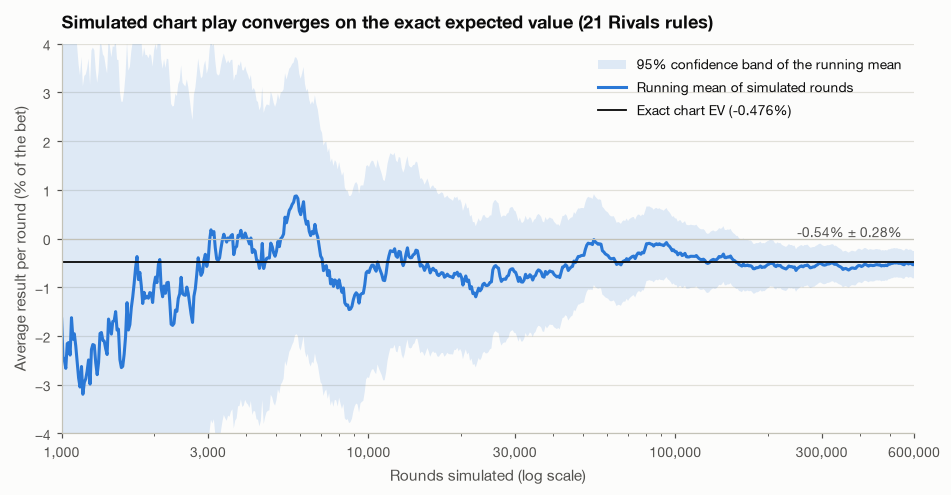

In [12]:
n = np.arange(1, N_ROUNDS + 1)
running = np.cumsum(nets) / n
running_sd = np.sqrt(np.maximum(np.cumsum(nets ** 2) / n - running ** 2, 0) * n / np.maximum(n - 1, 1))
half_width = 1.96 * running_sd / np.sqrt(n)
show = n >= 1000
idx = np.unique(np.geomspace(1000, N_ROUNDS, 600).astype(int)) - 1  # thin the points for plotting

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.fill_between(n[idx], 100 * (running - half_width)[idx], 100 * (running + half_width)[idx],
                color=BLUE, alpha=0.14, linewidth=0, label="95% confidence band of the running mean")
ax.plot(n[idx], 100 * running[idx], color=BLUE, lw=2, label="Running mean of simulated rounds")
ax.axhline(100 * exact.ev, color=INK, lw=1.2, label=f"Exact chart EV ({exact.ev:+.3%})")
ax.axhline(0, color=AXIS, lw=0.8)
ax.set_xscale("log")
ax.set_xlim(1000, N_ROUNDS)
ax.set_ylim(-4, 4)
ax.yaxis.grid(True)
ax.set_axisbelow(True)
ax.set_xlabel("Rounds simulated (log scale)")
ax.set_ylabel("Average result per round (% of the bet)")
ax.set_xticks([1000, 3000, 10_000, 30_000, 100_000, 300_000, 600_000])
ax.set_xticklabels(["1,000", "3,000", "10,000", "30,000", "100,000", "300,000", "600,000"])
ax.set_title("Simulated chart play converges on the exact expected value (21 Rivals rules)")
ax.annotate(f"{running[-1]:+.2%} ± {half_width[-1]:.2%}", xy=(N_ROUNDS, 100 * running[-1]),
            xytext=(-8, 18), textcoords="offset points", ha="right", fontsize=9, color=INK2)
ax.legend(loc="upper right", ncol=1)
plt.show()

The mean is only half the check: the project cares about the whole distribution of a round, so the simulated frequency of every result from −4 to +4 units is compared with the exact distribution from `round_value().dist`. The right panel shows each difference in standard errors (|z| < 2 is what noise alone produces about 95% of the time).

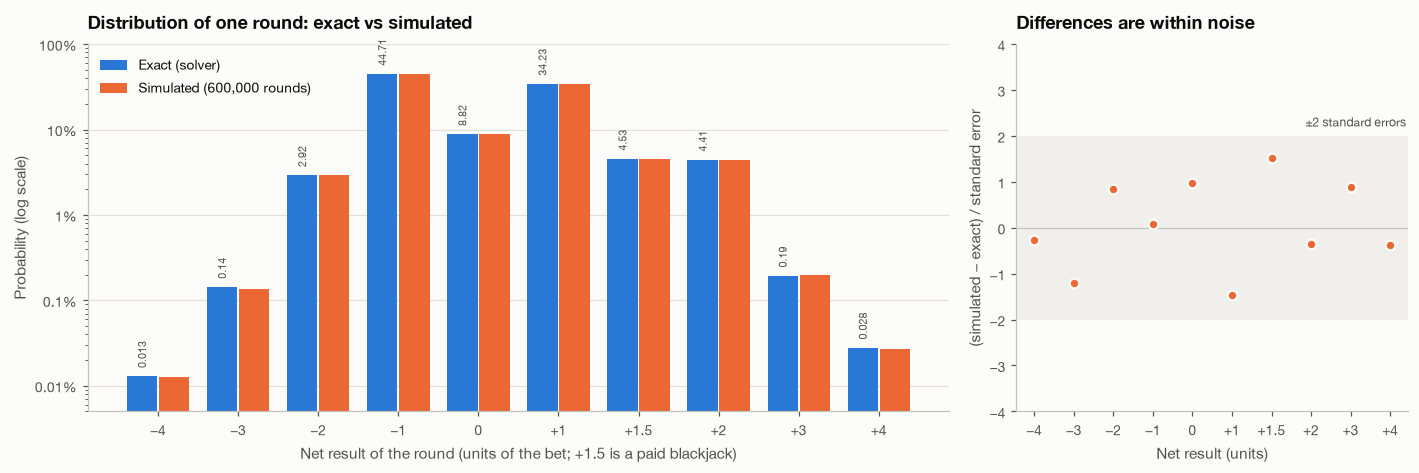

net units,exact,simulated,z
-4,0.0129%,0.0125%,-0.27
-3,0.1432%,0.1373%,-1.20
-2,2.9160%,2.9342%,+0.84
-1,44.7106%,44.7162%,+0.09
+0,8.8227%,8.8588%,+0.99
+1,34.2267%,34.1370%,-1.46
+1.5,4.5323%,4.5733%,+1.53
+2,4.4139%,4.4047%,-0.35
+3,0.1940%,0.1990%,+0.88
+4,0.0278%,0.0270%,-0.38


In [13]:
support = sorted(exact.dist)
values_sim, counts_sim = np.unique(nets, return_counts=True)
sim_p = dict(zip(values_sim.tolist(), (counts_sim / N_ROUNDS).tolist()))
dist_table = pd.DataFrame({"net units": support,
                           "exact": [exact.dist[x] for x in support],
                           "simulated": [sim_p.get(x, 0.0) for x in support]})
dist_table["z"] = (dist_table.simulated - dist_table.exact) / np.sqrt(dist_table.exact * (1 - dist_table.exact) / N_ROUNDS)
assert set(sim_p) <= set(support), "simulation produced a result the exact distribution does not have"

labels = [(f"{x:+g}" if x else "0").replace("-", "\u2212") for x in support]
xs = np.arange(len(support))
fig, (ax, az) = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [2.2, 1]})
ax.bar(xs - 0.2, 100 * dist_table.exact, width=0.38, color=BLUE, label="Exact (solver)")
ax.bar(xs + 0.2, 100 * dist_table.simulated, width=0.38, color=ORANGE, label=f"Simulated ({N_ROUNDS:,} rounds)")
ax.set_yscale("log")
ax.set_ylim(0.005, 100)
ax.set_yticks([0.01, 0.1, 1, 10, 100])
ax.set_yticklabels(["0.01%", "0.1%", "1%", "10%", "100%"])
ax.yaxis.grid(True)
ax.set_axisbelow(True)
ax.set_xticks(xs, labels)
ax.set_xlabel("Net result of the round (units of the bet; +1.5 is a paid blackjack)")
ax.set_ylabel("Probability (log scale)")
ax.set_title("Distribution of one round: exact vs simulated")
ax.legend(loc="upper left")
for x, p in zip(xs, dist_table.exact):
    ax.text(x - 0.2, 100 * p * 1.25, f"{100 * p:.2f}" if p >= 0.001 else f"{100 * p:.3f}",
            ha="center", va="bottom", fontsize=7, color=INK2, rotation=90)

az.axhspan(-2, 2, color=NEUTRAL, linewidth=0)
az.axhline(0, color=AXIS, lw=0.8)
az.scatter(xs, dist_table.z, s=40, color=ORANGE, edgecolor=SURFACE, linewidth=1.5, zorder=3)
az.set_xticks(xs, labels)
az.set_ylim(-4, 4)
az.set_xlabel("Net result (units)")
az.set_ylabel("(simulated − exact) / standard error")
az.set_title("Differences are within noise")
az.text(len(xs) - 0.6, 2.15, "±2 standard errors", ha="right", va="bottom", fontsize=8, color=INK2)
plt.tight_layout()
plt.show()

dist_table.style.format({"net units": "{:+g}", "exact": "{:.4%}", "simulated": "{:.4%}", "z": "{:+.2f}"}).hide(axis="index")

**What to conclude.** The simulated mean lands within its confidence band of the exact chart EV, and the simulated frequency of every result from −4 to +4 units matches the exact distribution within sampling noise, including the rare split-and-double outcomes at ±3 and ±4. Two engine-level details are worth knowing: the exact distribution's own mean differs from the exact EV by about 0.001 points, because the solver treats the two hands of a split as independent given the dealer's result (`docs/DECISIONS.md`, S3); and 600,000 rounds pin the EV down only to about ±0.3 points, which is why the edge has to come from the solver, not from simulation. (`docs/DECISIONS.md` reports a 16-million-round run that agreed to 0.9 standard errors.)

## 4. Deck-count sensitivity

DraftKings says 6 decks but this is not yet confirmed in the app. Each deck count below is a full re-solve (about 4–6 s each), with optimal play and with that deck count's own chart. Where a deck count's chart differs from the 6-deck chart, the 6-deck chart is also valued at that deck count, which is the cost of memorising the wrong chart.

In [14]:
DECKS = [1, 2, 4, 6, 8]
deck_rules = {d: RIVALS.with_(num_decks=d) for d in DECKS}
t0 = time.perf_counter()
deck_charts = {d: basic_chart(r) for d, r in deck_rules.items()}
deck_optimal = {d: solver_for(r).round_value() for d, r in deck_rules.items()}
print(f"optimal play solved for {len(DECKS)} deck counts in {time.perf_counter() - t0:.0f} s")

optimal play solved for 5 deck counts in 22 s


In [15]:
t0 = time.perf_counter()
deck_chart_play = {d: (values["21 Rivals"]["chart"] if d == 6 else Solver(r, strategy=deck_charts[d]).round_value())
                   for d, r in deck_rules.items()}
print(f"each deck count's own chart solved in {time.perf_counter() - t0:.0f} s")

each deck count's own chart solved in 22 s


In [16]:
t0 = time.perf_counter()
six = chart_cells(deck_charts[6])
deck_changes = {d: [k for k, label in chart_cells(deck_charts[d]).items() if label != six[k]] for d in DECKS}
six_chart_play = {d: (deck_chart_play[d] if not deck_changes[d] else Solver(r, strategy=deck_charts[6]).round_value())
                  for d, r in deck_rules.items()}
print(f"the 6-deck chart valued where it differs, in {time.perf_counter() - t0:.0f} s")

deck_table = pd.DataFrame({
    "house edge, optimal play": {d: v.house_edge for d, v in deck_optimal.items()},
    "house edge, own chart": {d: v.house_edge for d, v in deck_chart_play.items()},
    "house edge, 6-deck chart": {d: v.house_edge for d, v in six_chart_play.items()},
    "SD of one round": {d: v.std for d, v in deck_optimal.items()},
    "chart cells that differ from 6 decks": {d: len(c) for d, c in deck_changes.items()},
})
deck_table.index.name = "decks"
deck_table.style.format("{:.3%}", subset=deck_table.columns[:3]).format("{:.3f}", subset=["SD of one round"])

the 6-deck chart valued where it differs, in 10 s


,"house edge, optimal play","house edge, own chart","house edge, 6-deck chart",SD of one round,chart cells that differ from 6 decks
decks,,,,,
1,-0.052%,-0.009%,0.015%,1.109,8
2,0.270%,0.287%,0.289%,1.109,4
4,0.423%,0.429%,0.429%,1.105,0
6,0.473%,0.476%,0.476%,1.105,0
8,0.498%,0.500%,0.500%,1.106,0


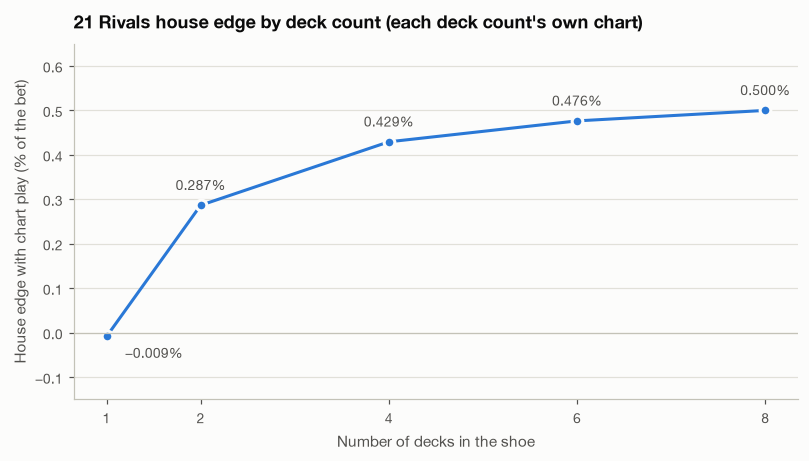

1 deck: 8 cells differ (hard 11 vs A: H -> Dh; hard 9 vs 2: H -> Dh; soft 19 (A,8) vs 6: S -> Ds; soft 18 (A,7) vs A: H -> S; 7,7 vs 8: H -> P; 6,6 vs 7: H -> P; 4,4 vs 4: H -> P; 3,3 vs 8: H -> P). Playing the 6-deck chart there costs 0.023% of the bet.
2 decks: 4 cells differ (hard 11 vs A: H -> Dh; hard 9 vs 2: H -> Dh; 7,7 vs 8: H -> P; 6,6 vs 7: H -> P). Playing the 6-deck chart there costs 0.003% of the bet.
4 decks: same chart as 6 decks
6 decks: same chart as 6 decks
8 decks: same chart as 6 decks


In [17]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
edges = [100 * deck_chart_play[d].house_edge for d in DECKS]
ax.plot(DECKS, edges, color=BLUE, lw=2, marker="o", markersize=7, markeredgecolor=SURFACE, markeredgewidth=2)
for d, e in zip(DECKS, edges):
    ax.annotate(f"{e:.3f}%".replace("-", "\u2212"), (d, e), xytext=(12, -14) if e < 0.05 else (0, 10),
                textcoords="offset points", ha="left" if e < 0.05 else "center", fontsize=9, color=INK2)
ax.axhline(0, color=AXIS, lw=0.8)
ax.set_xticks(DECKS)
ax.set_xlabel("Number of decks in the shoe")
ax.set_ylabel("House edge with chart play (% of the bet)")
ax.set_ylim(-0.15, 0.65)
ax.yaxis.grid(True)
ax.set_axisbelow(True)
ax.set_title("21 Rivals house edge by deck count (each deck count's own chart)")
plt.show()

for d in DECKS:
    changes = deck_changes[d]
    if not changes:
        print(f"{d} deck{'s' if d > 1 else ''}: same chart as 6 decks")
        continue
    listed = "; ".join(f"{cell_name(k)}: {six[k]} -> {chart_cells(deck_charts[d])[k]}" for k in changes)
    cost = six_chart_play[d].house_edge - deck_chart_play[d].house_edge
    print(f"{d} deck{'s' if d > 1 else ''}: {len(changes)} cells differ ({listed}). "
          f"Playing the 6-deck chart there costs {cost:.3%} of the bet.")

**What to conclude.** From 4 to 8 decks the chart is identical and the edge moves by less than 0.08 points; only a 1- or 2-deck shoe changes anything (doubling 9 vs 2 and 11 vs A, splitting 6,6 vs 7 and 7,7 vs 8, and four more cells at one deck), and even there the 6-deck chart costs at most a few hundredths of a point. The deck count therefore does not matter for the main bet. (It matters a great deal for the Perfect Pairs side bet, see notebook 02.)

## 5. Dealer outcomes by upcard

`Solver.dealer_probs(cards, upcard)` gives the dealer's finishing chances for a player who stands, after any blackjack check. A player hand with no cards removes only the upcard from the shoe: that is the neutral case, and it equals the average over every two-card hand the player could hold. Under 21 Rivals rules the **ten-up column includes the dealer blackjack the dealer did not check for**, while the **ace-up column is conditional on the dealer having checked and found no blackjack**, because with an ace up the round ends before you act if the dealer has one.

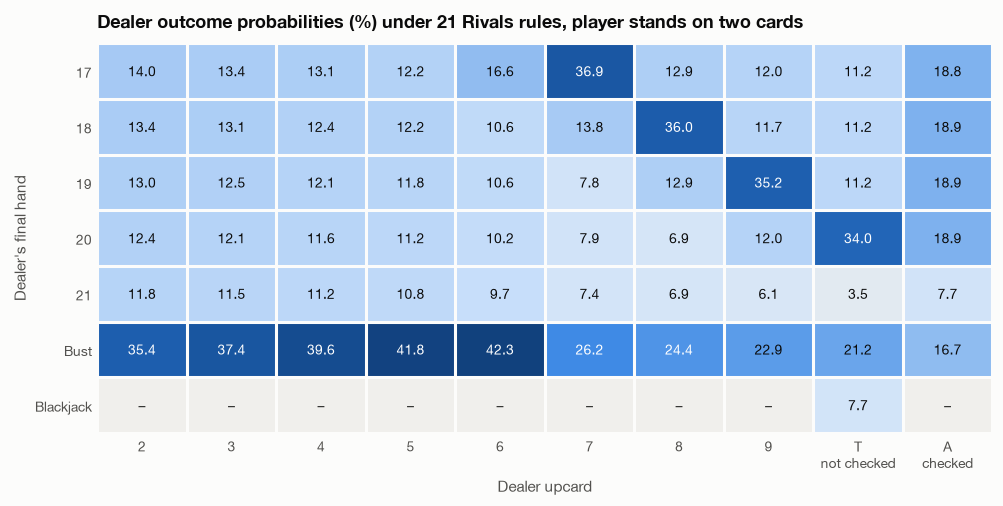

In [18]:
solver = solver_for(RIVALS)
UPCARD_CARDS = {VALUE_NAMES[u]: VALUE_NAMES[u] + "c" for u in UP_ORDER}
OUTCOMES = ["17", "18", "19", "20", "21", "bust", "blackjack"]
dealer = pd.DataFrame({name: solver.dealer_probs([], card) for name, card in UPCARD_CARDS.items()}).loc[OUTCOMES]

ramp = LinearSegmentedColormap.from_list("blue", ["#f0efec", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
fig, ax = plt.subplots(figsize=(10.5, 4.6))
data = 100 * dealer.values
ax.imshow(data, cmap=ramp, vmin=0, vmax=45, aspect="auto")
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        v = data[i, j]
        ax.text(j, i, "–" if v == 0 else f"{v:.1f}", ha="center", va="center", fontsize=9,
                color="#ffffff" if v > 24 else INK)
ax.set_xticks(range(len(UPCARD_CARDS)), [n if n not in ("T", "A") else
              {"T": "T\nnot checked", "A": "A\nchecked"}[n] for n in UPCARD_CARDS])
ax.set_yticks(range(len(OUTCOMES)), ["17", "18", "19", "20", "21", "Bust", "Blackjack"])
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks(np.arange(-0.5, len(UPCARD_CARDS)), minor=True)
ax.set_yticks(np.arange(-0.5, len(OUTCOMES)), minor=True)
ax.grid(which="minor", color=SURFACE, linewidth=2)
ax.tick_params(which="minor", length=0)
ax.set_xlabel("Dealer upcard")
ax.set_ylabel("Dealer's final hand")
ax.set_title("Dealer outcome probabilities (%) under 21 Rivals rules, player stands on two cards")
plt.show()

The checked and unchecked versions side by side: the textbook game checks under a ten, and switching off the check under an ace shows the ace column before the check.

In [19]:
checked_ten = solver_for(TEXTBOOK).dealer_probs([], "Tc")
unchecked_ace = Solver(RIVALS.with_(dealer_peeks_on_ace=False)).dealer_probs([], "Ac")
compare = pd.DataFrame({
    "T up, 21 Rivals (no check)": dealer["T"],
    "T up, textbook (checked, no blackjack)": pd.Series(checked_ten),
    "A up, before the check": pd.Series(unchecked_ace),
    "A up, after the check (both games)": dealer["A"],
}).loc[OUTCOMES]
compare.style.format("{:.2%}")

,"T up, 21 Rivals (no check)","T up, textbook (checked, no blackjack)","A up, before the check","A up, after the check (both games)"
17,11.19%,12.13%,13.00%,18.81%
18,11.17%,12.10%,13.08%,18.92%
19,11.19%,12.13%,13.06%,18.89%
20,34.00%,36.84%,13.09%,18.94%
21,3.48%,3.77%,5.35%,7.74%
bust,21.25%,23.02%,11.55%,16.70%
blackjack,7.72%,0.00%,30.87%,0.00%


In [20]:
# How much do the player's own two cards move the dealer's bust chance? (all 55 two-card hands by value)
hands = [f"{VALUE_NAMES[a]}s {VALUE_NAMES[b]}h" for a in range(10) for b in range(a, 10)]
bust = pd.DataFrame({name: [solver.dealer_probs(h, card)["bust"] for h in hands]
                     for name, card in UPCARD_CARDS.items()}, index=hands)
spread = pd.DataFrame({"no player cards": dealer.loc["bust"], "lowest": bust.min(), "highest": bust.max(),
                       "hand giving the lowest": bust.idxmin().str.replace("s ", "-").str.replace("h", ""),
                       "hand giving the highest": bust.idxmax().str.replace("s ", "-").str.replace("h", "")})
spread.style.format("{:.2%}", subset=["no player cards", "lowest", "highest"])

,no player cards,lowest,highest,hand giving the lowest,hand giving the highest
2,35.35%,35.04%,35.64%,T-T,5-5
3,37.42%,37.11%,37.74%,T-T,5-5
4,39.58%,39.27%,39.93%,T-T,5-5
5,41.84%,41.54%,42.22%,T-T,5-5
6,42.28%,41.98%,42.72%,T-T,A-A
7,26.19%,25.90%,26.41%,9-9,A-A
8,24.37%,24.12%,24.56%,8-8,A-A
9,22.92%,22.72%,23.10%,7-7,A-A
T,21.25%,21.09%,21.42%,6-6,A-A
A,16.70%,16.49%,17.03%,T-T,6-6


**What to conclude.** The familiar pattern holds: the dealer busts most often with a 5 or 6 up (about 42%) and least with a ten (21%) or a checked ace (17%). The 21 Rivals-specific point is the ten-up column: a 7.7% chance of blackjack that has not been ruled out sits inside every decision against a ten, and that is what moves 11 vs T and 8,8 vs T in the chart. With a ten up the dealer reaches 20 or 21 or has blackjack 45% of the time, against 41% in the checked textbook game. Your own two cards move the bust chance by less than half a percentage point either way, so the table is a fair summary for every hand.

## Summary

* The derived textbook chart matches the published 6-deck S17 DAS chart cell for cell, and every 21 Rivals change has a rule-level explanation.
* House edge under 21 Rivals rules: **0.473%** optimal, **0.476%** with the chart; one round has a standard deviation of **1.105 units**. Both agree with `docs/DECISIONS.md`.
* 600,000 simulated rounds through `play_round` agree with the exact mean and with every point of the exact −4…+4 distribution, within noise.
* From 4 to 8 decks the chart does not change; the edge moves from 0.43% to 0.50%.
* Against a ten, the dealer's unchecked blackjack (7.7%) is part of every decision.